In [97]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from scipy.stats import chi2_contingency
from scipy.stats.contingency import association
import scipy.stats as stats

%matplotlib inline

In [3]:
df = pd.read_csv("C:/Users/Janak ARORA/Desktop/Ironhack_files/Week_5/Day1/amz_uk_price_prediction_dataset.csv/amz_uk_price_prediction_dataset.csv")
df

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers
...,...,...,...,...,...,...,...,...,...
2443646,2828589,B0CHSD7P2Q,"Motorbike Armour, Motorbike Clothing, Cycling ...",0.0,0,22.34,False,0,Motorbike Clothing
2443647,2828590,B0B7B8FNBQ,PROFIRST Waterproof Motorcycle 2 Piece Ladies ...,0.0,0,97.99,False,0,Motorbike Clothing
2443648,2828591,B0BD5FL5FB,Men’s Motorcycle Motorbike Biker Trousers Kevl...,0.0,0,52.99,False,0,Motorbike Clothing
2443649,2828592,B008OYLL4I,Texpeed Mens Motorcycle Motorbike Biker Trouse...,4.3,404,79.99,False,0,Motorbike Clothing


# Part 1: Analyzing Best-Seller Trends Across Product Categories

In [90]:
# 1. Crosstab Analysis:

# 1.1 Create a crosstab between the product category and the isBestSeller status.

best_seller = df['isBestSeller']
product_category = df['category']

crosstab_results = pd.crosstab(best_seller, product_category, margins=True)
(crosstab_results)

category,3D Printers,3D Printing & Scanning,Abrasive & Finishing Products,Action Cameras,Adapters,Agricultural Equipment & Supplies,Alexa Built-In Devices,Art & Craft Supplies,Arts & Crafts,Baby,...,Vacuums & Floorcare,Vases,"Water Coolers, Filters & Cartridges",Wearable Technology,Wind Instruments,Window Treatments,Women,Women's Sports & Outdoor Shoes,eBook Readers & Accessories,All
isBestSeller,,,,,,,,,,,,,,,,,,,,,
False,247,4065,245,1696,251,8421,106,253,9319,14709,...,6919,250,186,8876,243,234,17559,1939,246,2435671
True,1,2,5,1,3,109,1,5,230,341,...,26,0,1,30,7,5,213,20,0,7980
All,248,4067,250,1697,254,8530,107,258,9549,15050,...,6945,250,187,8906,250,239,17772,1959,246,2443651


In [86]:
# 1.2 Are there categories where being a best-seller is more prevalent?

# Calculate proportion of best-sellers per category
# (Assumes True indicates a best-seller)
crosstab_results["bestseller_proportion"] = (crosstab_results.get(True, 0) / crosstab_results.sum(axis=1))

# Sort categories by best-seller proportion
bestseller_prevalence = crosstab_results.sort_values(by="bestseller_proportion",ascending=False)

# Display top categories
print("Categories with highest best-seller prevalence:")
print(bestseller_prevalence[["bestseller_proportion"]].head())

Categories with highest best-seller prevalence:
category      bestseller_proportion
isBestSeller                       
False                           0.0
True                            0.0
All                             0.0


In [46]:
# 2. Statistical Tests:

# 2.1 Conduct a Chi-square test to determine if the best-seller distribution is independent of the product category.

print("Filtered Contingency Table Shape:", crosstab_results.shape)

chi2, p_value, dof, expected = chi2_contingency(crosstab_results)

#print("\nChi-square Test Results:")
print(f"Chi-square statistic: {chi2:.4f}")
print(f"Degrees of freedom: {dof}")
print(f"P-value: {p_value:.6f}")

Filtered Contingency Table Shape: (3, 297)
Chi-square statistic: 36540.2027
Degrees of freedom: 592
P-value: 0.000000


In [47]:
# 2.2 Compute Cramér's V to understand the strength of association between best-seller status and category.

association(crosstab_results, method="cramer")

0.043233549454462075

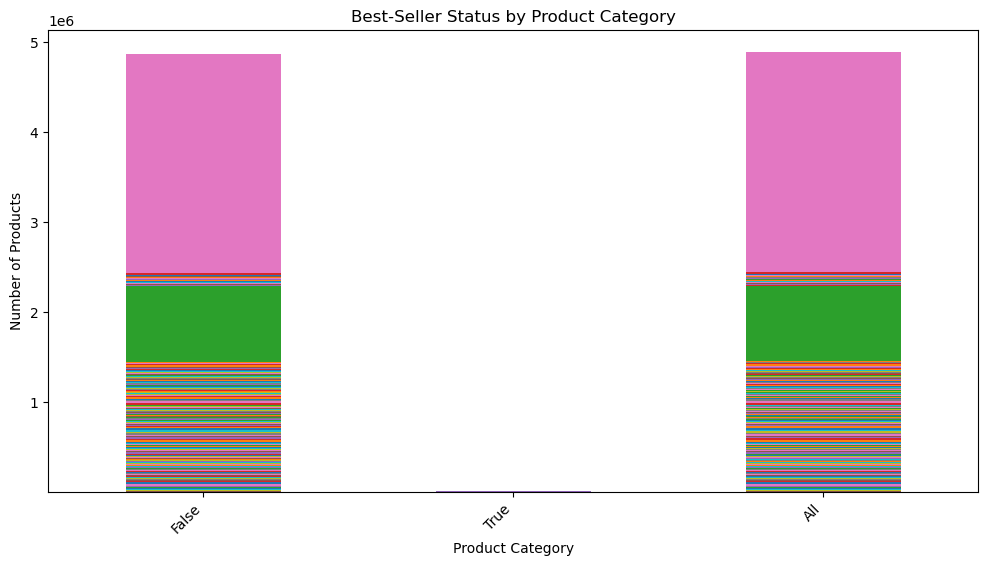

In [89]:
# 3. Visualizations:

# 3.1 Visualize the relationship between product categories and the best-seller status using a stacked bar chart.

# Plot stacked bar chart

crosstab_results.plot(
    kind="bar",
    stacked=True,
    legend=False,
    figsize=(12, 6)
)

plt.title("Best-Seller Status by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Number of Products")
plt.xticks(rotation=45, ha="right")
plt.show()

# Part 2: Exploring Product Prices and Ratings Across Categories and Brands

In [55]:
# Remove outliers in product prices.

# Ensure prices are numeric
df['price'] = pd.to_numeric(df['price'], errors="coerce")

# Drop missing prices
df = df.dropna(subset=['price'])

# Calculate IQR
Q1 = df['price'].quantile(0.25)
Q3 = df['price'].quantile(0.75)
IQR = Q3 - Q1

# Define bounds
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# Remove outliers
df_no_outliers = df[
    (df['price'] >= lower_bound) &
    (df['price'] <= upper_bound)
]

print(f"Original rows: {len(df)}")
print(f"Rows after outlier removal: {len(df_no_outliers)}")

Original rows: 2443651
Rows after outlier removal: 2115963


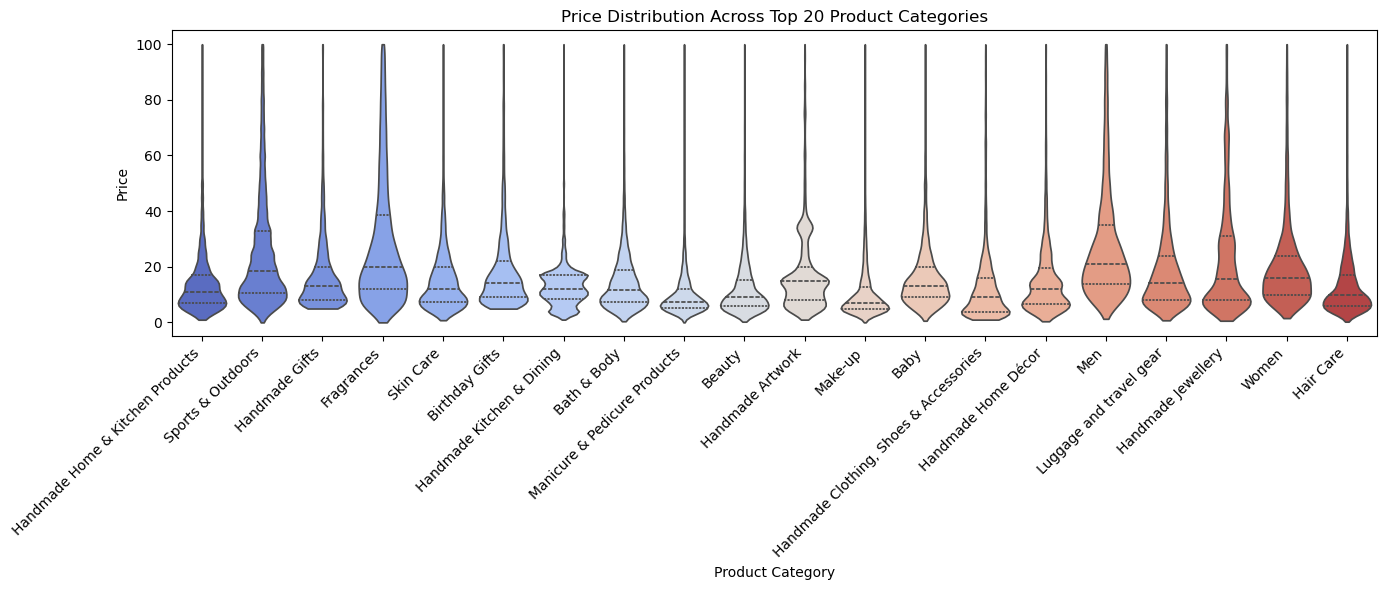

In [61]:
# 1. Violin Plots:

# 1.1 Use a violin plot to visualize the distribution of price across different product categories. 
# Filter out the top 20 categories based on count for better visualization.

# Select top 20 categories by product count
top_20_categories = (
    df_no_outliers['category']
    .value_counts()
    .head(20)
    .index
)

# Filter dataset
df_top20 = df_no_outliers[df_no_outliers['category'].isin(top_20_categories)]

# Plot violin chart
plt.figure(figsize=(14, 6))

sns.violinplot(
    data=df_top20, 
    x='category', 
    y='price', 
    palette="coolwarm",
    hue='category',
    inner="quartile",
    cut=0
)

plt.title("Price Distribution Across Top 20 Product Categories")
plt.xlabel("Product Category")
plt.ylabel("Price")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [75]:
# 1.2 Which product category tends to have the highest median price? Don't filter here by top categories.

# Calculate median price per category
median_prices = (
    df_no_outliers.groupby('category')['price']
      .median()
      .sort_values(ascending=False)
)

# Display top result
print("Categories with the highest median price:")
print(median_prices)

Categories with the highest median price:
category
Desktop PCs              74.00
Boxing Shoes             69.79
Tablets                  69.00
Graphics Cards           68.54
Motherboards             67.92
                         ...  
Adapters                  7.05
Make-up                   7.00
Signs & Plaques           6.99
Arts & Crafts             5.99
Office Paper Products     4.37
Name: price, Length: 296, dtype: float64


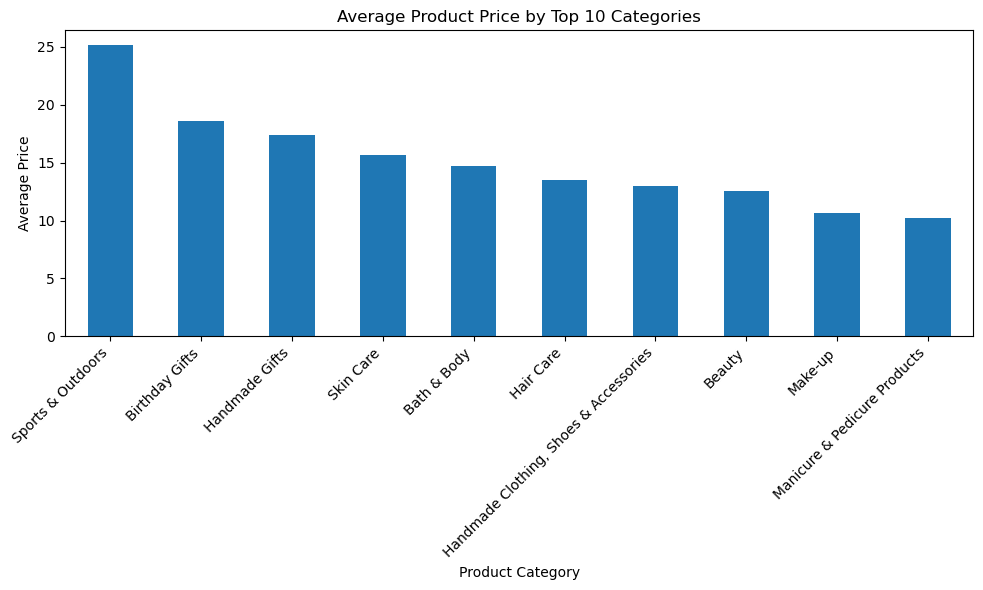

In [66]:
# 2. Bar Charts:
# 2.1 Create a bar chart comparing the average price of products for the top 10 product categories (based on count).

# Select top 20 categories by product count
top_10_categories = (
    df_no_outliers['category']
    .value_counts()
    .head(10)
    .index
)

# Filter dataset
df_top10 = df_no_outliers[df_no_outliers['category'].isin(top_10_categories)]

# Calculate average price per category
avg_price_by_category = (
    df_top10
    .groupby('category')['price']
    .mean()
    .sort_values(ascending=False)
)

# Plot bar chart
plt.figure(figsize=(10, 6))
avg_price_by_category.plot(kind="bar")

plt.title("Average Product Price by Top 10 Categories")
plt.xlabel("Product Category")
plt.ylabel("Average Price")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [74]:
# 2.2 Which product category commands the highest average price? Don't filter here by top categories.

# Calculate average price per category
avg_prices = (
    df_no_outliers.groupby('category')['price']
      .mean()
      .sort_values(ascending=False)
)

# Category with highest average price
print("Categories with the highest average price:")
print(avg_prices.head())

Categories with the highest average price:
category
Motherboards      68.772432
Boxing Shoes      67.417803
Desktop PCs       66.915562
Tablets           66.552971
Graphics Cards    65.103509
Name: price, dtype: float64


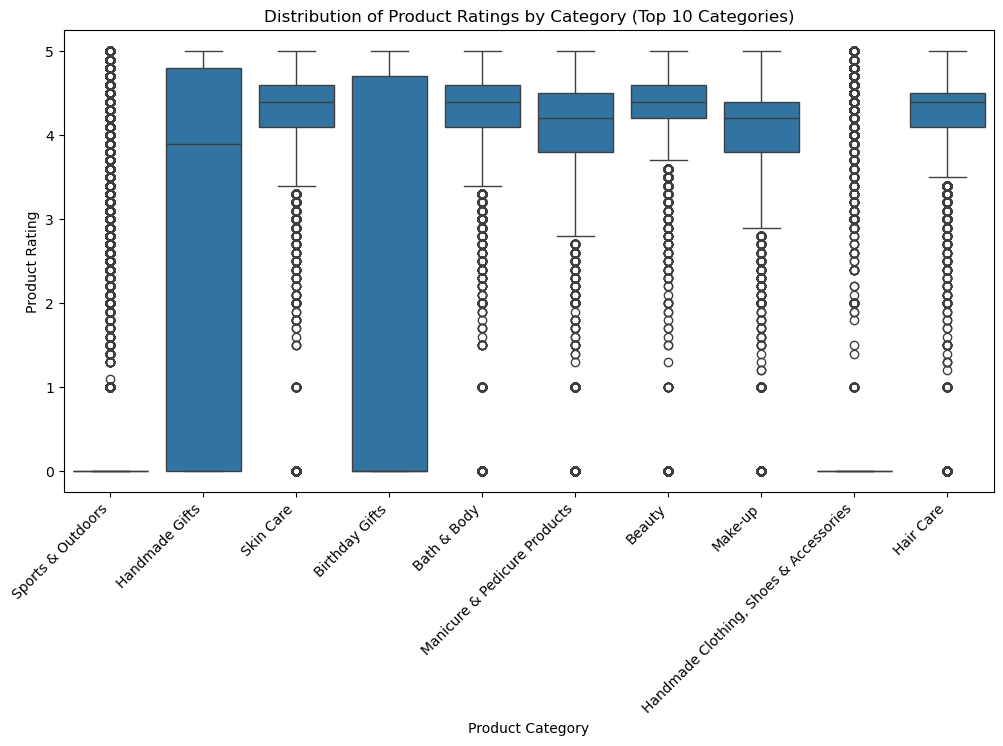

In [73]:
# 3. Box Plots:

# 3.1 Visualize the distribution of product ratings based on their category using side-by-side box plots. 
# Filter out the top 10 categories based on count for better visualization.

# Plot side-by-side box plots
plt.figure(figsize=(12, 6))
sns.boxplot(
    data=df_top10,
    x='category',
    y='stars'
)

plt.title("Distribution of Product Ratings by Category (Top 10 Categories)")
plt.xlabel("Product Category")
plt.ylabel("Product Rating")
plt.xticks(rotation=45, ha="right")
plt.show()

In [76]:
# 3.2 Which category tends to receive the highest median rating from customers? Don't filter here by top categories.

# Calculate median rating per category
median_ratings = (
    df_no_outliers.groupby('category')['stars']
      .median()
      .sort_values(ascending=False)
)

# Category with the highest median rating
print("Categories with the highest median rating:")
print(median_ratings)

Categories with the highest median rating:
category
Computer Memory                                 4.7
Beer, Wine & Spirits                            4.6
Building & Construction Toys                    4.6
Office Paper Products                           4.6
Kids' Play Figures                              4.6
                                               ... 
Synthesisers, Samplers & Digital Instruments    0.0
Tablets                                         0.0
Action Cameras                                  0.0
3D Printing & Scanning                          0.0
eBook Readers & Accessories                     0.0
Name: stars, Length: 296, dtype: float64


# Part 3: Investigating the Interplay Between Product Prices and Ratings

In [91]:
# 1. Correlation Coefficients:

# 1.1 Calculate the correlation coefficient between price and stars.

# Ensure numeric values
df['price'] = pd.to_numeric(df['price'], errors="coerce")
df['stars'] = pd.to_numeric(df['stars'], errors="coerce")

# Drop rows with missing values
df_corr = df.dropna(subset=['price', 'stars'])

# Calculate correlation
correlation = df_corr['price'].corr(df_corr['stars'])

print(f"Correlation coefficient between price and stars: {correlation:.3f}")

Correlation coefficient between price and stars: -0.078


In [ ]:
# 1.2 Is there a significant correlation between product price and its rating?

# There is no significant practical correlation between product price and customer rating. 
    # While minor correlations may exist, they are weak, indicating that higher prices do not reliably translate into better customer ratings.

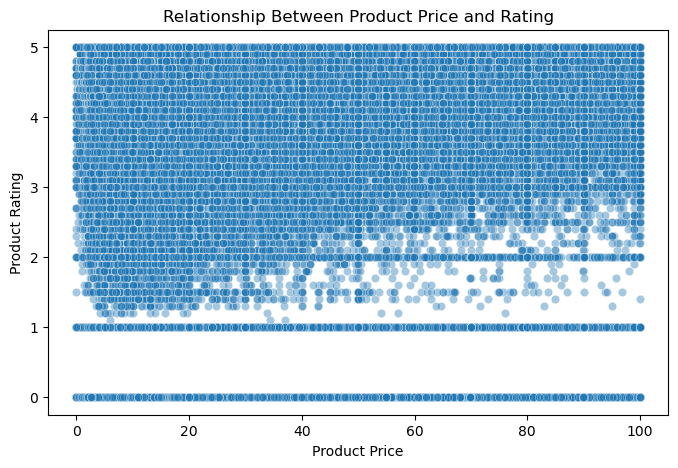

In [95]:
# 2. Visualizations:

# 2.1 Use a scatter plot to visualize the relationship between product rating and price. What patterns can you observe?

# Ensure numeric values
df['price'] = pd.to_numeric(df['price'], errors="coerce")
df['stars'] = pd.to_numeric(df['stars'], errors="coerce")

# Drop missing values
df_scatter = df.dropna(subset=['price', 'stars'])

# Scatter plot
plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=df_scatter,
    x='price',
    y='stars',
    alpha=0.4
)

plt.title("Relationship Between Product Price and Rating")
plt.xlabel("Product Price")
plt.ylabel("Product Rating")
plt.show()

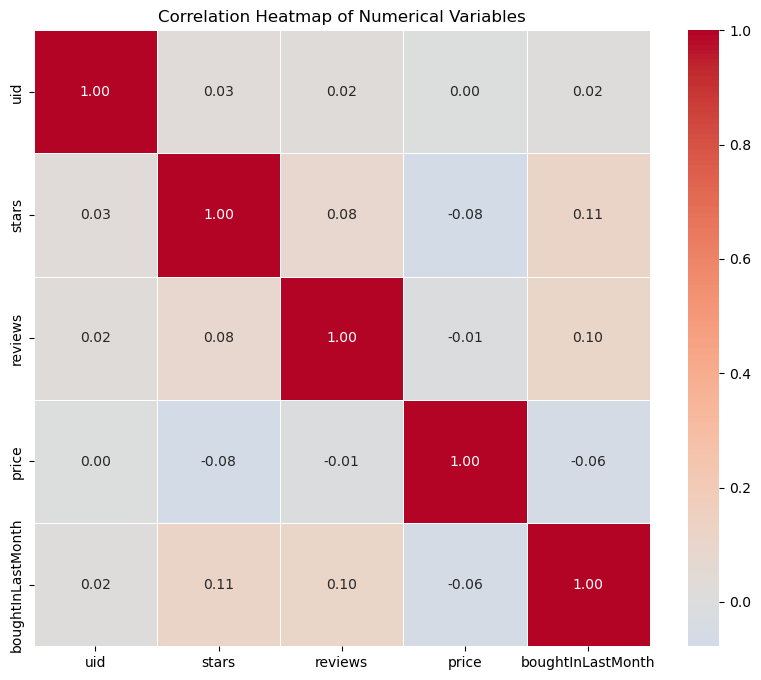

In [94]:
# 2.2 Use a correlation heatmap to visualize correlations between all numerical variables.

# Select all numerical columns
numeric_df = df.select_dtypes(include=["int64", "float64"])

# Compute correlation matrix
corr_matrix = numeric_df.corr()

# Plot heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    square=True,
    linewidths=0.5
)

plt.title("Correlation Heatmap of Numerical Variables")
plt.show()

<Figure size 600x600 with 0 Axes>

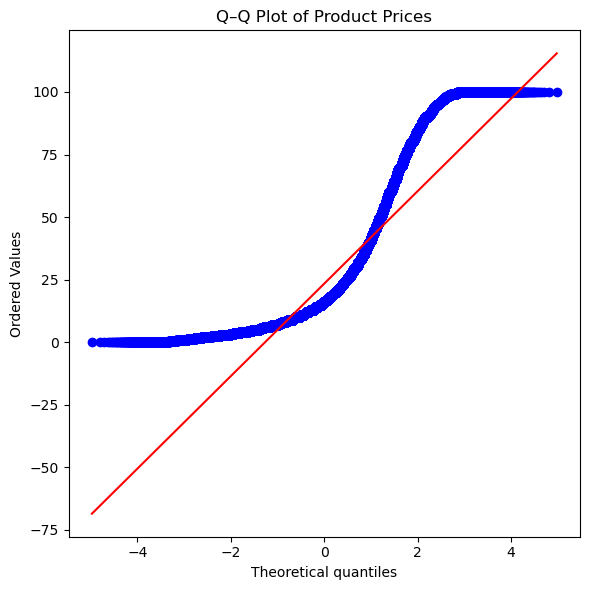

In [98]:
# 2.3 Examine if product prices typically follow a normal distribution using a QQ plot.

# Ensure prices are numeric and drop missing values
df['price'] = pd.to_numeric(df['price'], errors="coerce")
prices = df['price'].dropna()

# Q-Q plot
plt.figure(figsize=(6, 6))
stats.probplot(prices, dist="norm", plot=plt)
plt.title("Q–Q Plot of Product Prices")
plt.tight_layout()
plt.show()